In [ ]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Train/Test
from sklearn.model_selection import train_test_split

# Models
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df = pd.read_csv("diabetic_data.csv")
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
# # Replace ? with NaN
df.replace("?", np.nan, inplace=True)

# Remove extra spaces in column names
df.columns = df.columns.str.strip()

# Drop unnecessary columns safely
cols_to_drop = ["encounter_id","patient_nbr", "weight", "payer_code", "medical_specialty"]
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# Fill categorical
df.fillna({col: df[col].mode()[0] for col in df.select_dtypes(include='object')}, inplace=True)

# Fill numerical
df.fillna({col: df[col].median() for col in df.select_dtypes(include=['int64','float64'])}, inplace=True)

print("Missing values handled successfully!")

print("After handling missing values:", df.shape)

Missing values handled successfully!
After handling missing values: (101766, 45)


In [ ]:
df.drop_duplicates(inplace=True)
print("After removing duplicates:", df.shape)

After removing duplicates: (101766, 45)


In [ ]:
df['readmitted'] = df['readmitted'].replace({
    '>30': 0,
    'NO': 0,
    '<30': 1
}).astype(int)

/tmp/ipykernel_3372/474809456.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['readmitted'] = df['readmitted'].replace({


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Create a dictionary to store a LabelEncoder for each categorical column
label_encoders_dict = {}

for col in df.select_dtypes(include='object'):
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders_dict[col] = le # Save the fitted encoder

print("All categorical columns encoded and encoders saved to label_encoders_dict.")

All categorical columns encoded and encoders saved to label_encoders_dict.


In [ ]:
df['previous_admissions'] = df['number_inpatient'] + df['number_emergency']



In [ ]:
df['medication_load'] = df['num_medications']

In [ ]:
df['time_since_last_visit'] = (
    df['number_outpatient'] * 30 +
    df['number_inpatient'] * 60 +
    df['number_emergency'] * 15
)

In [ ]:
def safe_float(x):
    try:
        return float(x)
    except:
        return 0

df['diag_1_num'] = df['diag_1'].apply(safe_float)
df['diag_2_num'] = df['diag_2'].apply(safe_float)
df['diag_3_num'] = df['diag_3'].apply(safe_float)

In [ ]:
def severity_score(code):
    if 390 <= code <= 459:
        return 3   # circulatory (high risk)
    elif 460 <= code <= 519:
        return 2   # respiratory
    elif 520 <= code <= 579:
        return 2   # digestive
    elif code == 250:
        return 3   # diabetes
    elif 800 <= code <= 999:
        return 1   # injury
    else:
        return 0   # others

In [ ]:
df['diag_severity'] = (
    df['diag_1_num'].apply(severity_score) +
    df['diag_2_num'].apply(severity_score) +
    df['diag_3_num'].apply(severity_score)
)

In [ ]:
X = df.drop('readmitted', axis=1)
y = df['readmitted']

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X, y)

print("After SMOTE:", X_res.shape)

After SMOTE: (180818, 51)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy (Random Forest):", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy (Random Forest): 0.9179017807764628
              precision    recall  f1-score   support

           0       0.89      0.96      0.92     17972
           1       0.95      0.88      0.92     18192

    accuracy                           0.92     36164
   macro avg       0.92      0.92      0.92     36164
weighted avg       0.92      0.92      0.92     36164



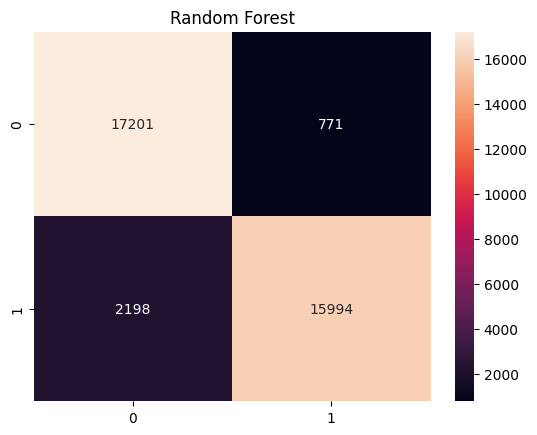

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d')
plt.title("Random Forest")
plt.show()

In [ ]:
pip install xgboost

In [ ]:
import sys
!{sys.executable} -m pip install xgboost

In [ ]:

from xgboost import XGBClassifier
print("XGBoost imported successfully!")

XGBoost imported successfully!


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.8839453600265458
              precision    recall  f1-score   support

           0       0.85      0.93      0.89     17972
           1       0.92      0.84      0.88     18192

    accuracy                           0.88     36164
   macro avg       0.89      0.88      0.88     36164
weighted avg       0.89      0.88      0.88     36164



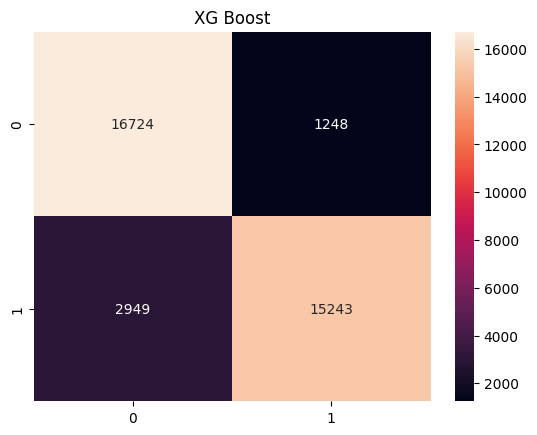

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_test, y_pred_xgb), annot=True, fmt='d')
plt.title("XG Boost")
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Train model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

# Predictions
y_pred_lr = lr_model.predict(X_test)
y_pred_proba_lr = lr_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))


Logistic Regression Accuracy: 0.8118017918371861
              precision    recall  f1-score   support

           0       0.78      0.86      0.82     17972
           1       0.85      0.76      0.80     18192

    accuracy                           0.81     36164
   macro avg       0.82      0.81      0.81     36164
weighted avg       0.82      0.81      0.81     36164



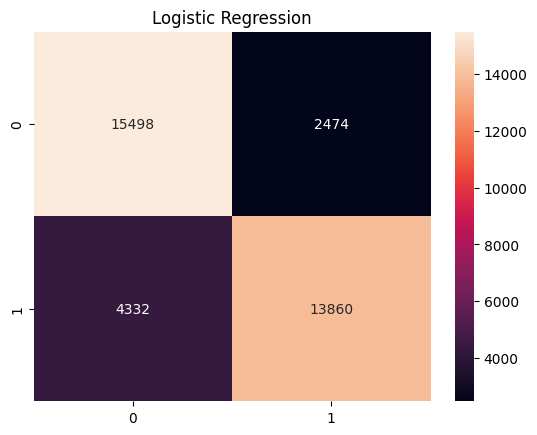

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Logistic Regression
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d')
plt.title("Logistic Regression")
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Train model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_model.predict(X_test)
y_pred_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))


Decision Tree Accuracy: 0.8431865944032739
              precision    recall  f1-score   support

           0       0.86      0.82      0.84     17972
           1       0.83      0.87      0.85     18192

    accuracy                           0.84     36164
   macro avg       0.84      0.84      0.84     36164
weighted avg       0.84      0.84      0.84     36164



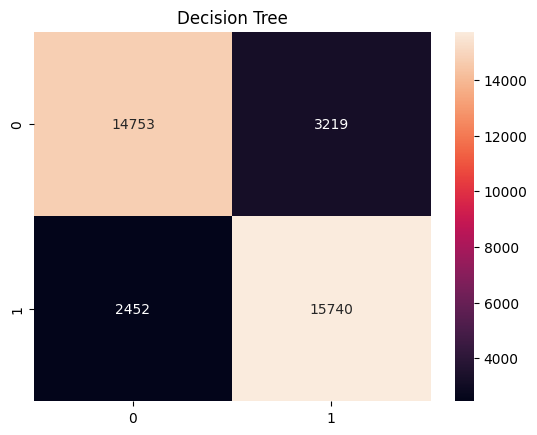

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d')
plt.title("Decision Tree")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

acc_dt = accuracy_score(y_test, y_pred_dt)
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_xgb = accuracy_score(y_test, y_pred_xgb)
acc_rf = accuracy_score(y_test, y_pred_rf)
print("Decision Tree Accuracy:", acc_dt)
print("Logistic Regression Accuracy:", acc_lr)
print("XGBoost Accuracy:", acc_xgb)
print("Random Forest Accuracy:", acc_rf)

Decision Tree Accuracy: 0.8431865944032739
Logistic Regression Accuracy: 0.8118017918371861
XGBoost Accuracy: 0.8839453600265458
Random Forest Accuracy: 0.9179017807764628


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Random Forest", "Decision Tree", "Logistic Regression", "XGBoost"],
    "Accuracy": [acc_rf, acc_dt, acc_lr, acc_xgb]
})

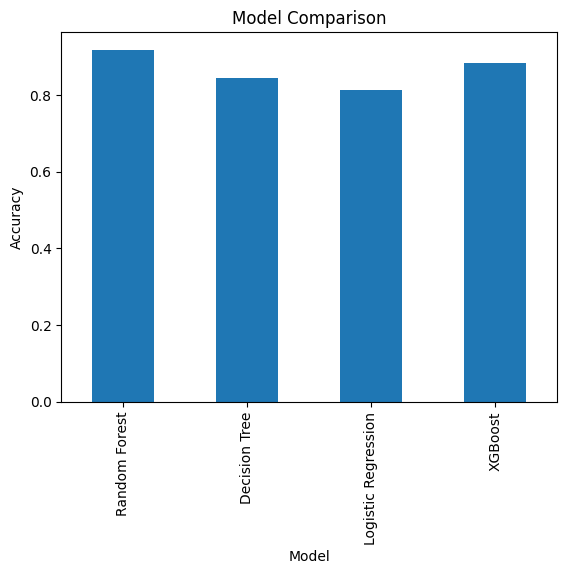

In [ ]:
import matplotlib.pyplot as plt

results.plot(x="Model", y="Accuracy", kind="bar", legend=False)
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.show()

In [ ]:
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score
import pandas as pd

model_names = ['Random Forest', 'Decision Tree', 'Logistic Regression', 'XGBoost']
y_preds = {
    'Random Forest': y_pred_rf,
    'Decision Tree': y_pred_dt,
    'Logistic Regression': y_pred_lr,
    'XGBoost': y_pred_xgb
}
y_pred_probas = {
    'Random Forest': y_pred_proba_rf,
    'Decision Tree': y_pred_proba_dt,
    'Logistic Regression': y_pred_proba_lr,
    'XGBoost': y_pred_proba_xgb
}

results_data = []

for model_name in model_names:
    y_pred = y_preds[model_name]
    y_pred_proba = y_pred_probas[model_name]

    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    report = classification_report(y_test, y_pred, output_dict=True)

    # Extract class 0 metrics
    precision_0 = report['0']['precision']
    recall_0 = report['0']['recall']
    f1_score_0 = report['0']['f1-score']

    # Extract class 1 metrics
    precision_1 = report['1']['precision']
    recall_1 = report['1']['recall']
    f1_score_1 = report['1']['f1-score']

    results_data.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'ROC-AUC': roc_auc,
        'Precision_0': precision_0,
        'Recall_0': recall_0,
        'F1-Score_0': f1_score_0,
        'Precision_1': precision_1,
        'Recall_1': recall_1,
        'F1-Score_1': f1_score_1
    })

metrics_df = pd.DataFrame(results_data)
print(metrics_df.to_string())


                 Model  Accuracy   ROC-AUC  Precision_0  Recall_0  F1-Score_0  Precision_1  Recall_1  F1-Score_1
0        Random Forest  0.917902  0.962199     0.886695  0.957100    0.920553     0.954011  0.879178    0.915067
1        Decision Tree  0.843187  0.843052     0.857483  0.820888    0.838787     0.830213  0.865215    0.847353
2  Logistic Regression  0.811802  0.884954     0.781543  0.862341    0.819957     0.848537  0.761873    0.802873
3              XGBoost  0.883945  0.935105     0.850099  0.930559    0.888511     0.924322  0.837896    0.878990


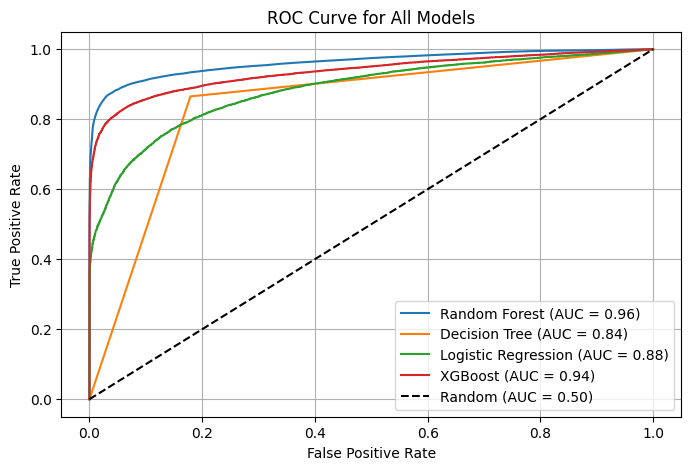

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Ensure all model probability predictions are available
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_proba_dt = dt_model.predict_proba(X_test)[:, 1]

# Re-predict for Logistic Regression if y_pred_proba_lr is not defined
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
y_pred_proba_lr = lr_model.predict_proba(X_test)[:, 1]

# Re-predict for XGBoost if y_pred_proba_xgb is not defined
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Now define model_names and y_pred_probas dictionary
model_names = ['Random Forest', 'Decision Tree', 'Logistic Regression', 'XGBoost']
y_pred_probas = {
    'Random Forest': y_pred_proba_rf,
    'Decision Tree': y_pred_proba_dt,
    'Logistic Regression': y_pred_proba_lr,
    'XGBoost': y_pred_proba_xgb
}

plt.figure(figsize=(8, 5))

for model_name in model_names:
    y_pred_proba = y_pred_probas[model_name]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    auc_score = roc_auc_score(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc_score:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
#from sklearn.model_selection import cross_val_score
#from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model (as defined previously)
#rf_model_cv = RandomForestClassifier(n_estimators=100, random_state=42)

# Perform 5-fold cross-validation on the resampled data
#cv_scores = cross_val_score(rf_model_cv, X_res, y_res, cv=5, scoring='accuracy')

#print("Cross-validation scores for Random Forest:", cv_scores)
#print("Mean cross-validation accuracy:", cv_scores.mean())

In [ ]:
#from sklearn.model_selection import cross_val_score
#from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model (as defined previously)
#rf_model_cv = RandomForestClassifier(n_estimators=100, random_state=42)

# Perform 10-fold cross-validation on the resampled data
#cv_scores = cross_val_score(rf_model_cv, X_res, y_res, cv=10, scoring='accuracy')

#print("Cross-validation scores for Random Forest:", cv_scores)
#print("Mean cross-validation accuracy:", cv_scores.mean())

In [ ]:
import joblib, json, os, shutil
import numpy as np
from sklearn.metrics import accuracy_score
from google.colab import files

os.makedirs("artifacts", exist_ok=True)

# compute accuracies fresh, don't rely on earlier cells
acc_rf = accuracy_score(y_test, y_pred_rf)
acc_dt = accuracy_score(y_test, y_pred_dt)
acc_lr = accuracy_score(y_test, y_pred_lr)
acc_xgb = accuracy_score(y_test, y_pred_xgb)

best_acc = max(acc_rf, acc_dt, acc_lr, acc_xgb)
if best_acc == acc_xgb:
    best_model, best_name = xgb_model, "xgboost"
elif best_acc == acc_rf:
    best_model, best_name = rf_model, "random_forest"
elif best_acc == acc_lr:
    best_model, best_name = lr_model, "logistic_regression"
else:
    best_model, best_name = dt_model, "decision_tree"

joblib.dump(best_model, "artifacts/model.joblib")
joblib.dump(scaler, "artifacts/scaler.joblib")
joblib.dump(label_encoders_dict, "artifacts/label_encoders_dict.joblib") # Save the dictionary of encoders
with open("artifacts/feature_columns.json", "w") as f:
    json.dump(list(X.columns), f)

print(f"Saved best model: {best_name} (accuracy {best_acc:.4f})")

# Save a sample of X_res for LIME's background data (Streamlit won't have X_res in memory)
sample_idx = np.random.RandomState(42).choice(len(X_res), size=min(2000, len(X_res)), replace=False)
lime_training_sample = X_res.values[sample_idx]
np.save("artifacts/lime_training_sample.npy", lime_training_sample)
print(f"Saved LIME background sample: {lime_training_sample.shape}")

shutil.make_archive("artifacts", "zip", "artifacts")
files.download("artifacts.zip")

Saved best model: random_forest (accuracy 0.9179)
Saved LIME background sample: (2000, 51)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 1. Load the Best Model and Preprocessing Tools

First, we'll load the saved best model, the `StandardScaler`, and the `LabelEncoder`, along with the list of feature columns, which were saved in the `artifacts.zip` file.

In [ ]:
import joblib
import json
import pandas as pd
import numpy as np

# Load the best model
best_model = joblib.load('artifacts/model.joblib')
print(f'Loaded best model: {type(best_model).__name__}')

# Load the scaler
scaler = joblib.load('artifacts/scaler.joblib')
print('Loaded StandardScaler.')

# Load the dictionary of label encoders
label_encoders_dict = joblib.load('artifacts/label_encoders_dict.joblib')
print('Loaded dictionary of LabelEncoders.')

# Load feature columns
with open('artifacts/feature_columns.json', 'r') as f:
    feature_columns = json.load(f)
print(f'Loaded {len(feature_columns)} feature columns.')

Loaded best model: RandomForestClassifier
Loaded StandardScaler.
Loaded dictionary of LabelEncoders.
Loaded 51 feature columns.


### 2. Define Feature Engineering Functions

We need to re-define the `safe_float` and `severity_score` functions used during training to apply them to new patient data.

In [ ]:
def safe_float(x):
    try:
        return float(x)
    except:
        return 0

def severity_score(code):
    if 390 <= code <= 459:
        return 3   # circulatory (high risk)
    elif 460 <= code <= 519:
        return 2   # respiratory
    elif 520 <= code <= 579:
        return 2   # digestive
    elif code == 250:
        return 3   # diabetes
    elif 800 <= code <= 999:
        return 1   # injury
    else:
        return 0   # others

In [ ]:
!pip install lime

Loaded model, scaler, encoders, and feature columns from artifacts.

--- Prediction Result ---
The model predicts: Patient IS likely to be readmitted (<30 days).
Prediction probabilities: 0.3400 (Not Readmitted), 0.6600 (Readmitted <30 Days)
Using globally available X_res for LIME training data.

--- LIME Explanation Plot for User Input ---



--- SHAP Force Plot for User Input ---


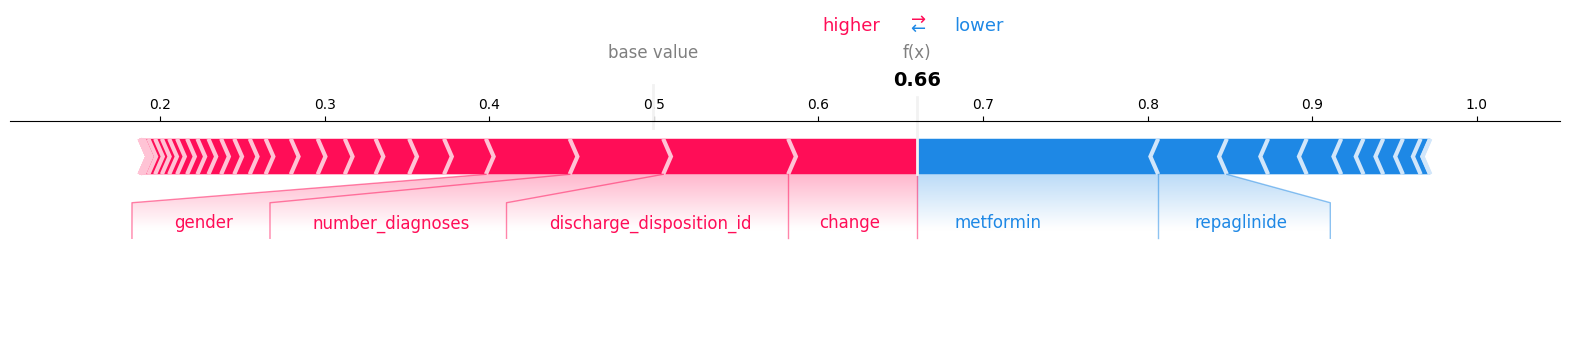


--- SHAP Waterfall Plot for User Input ---


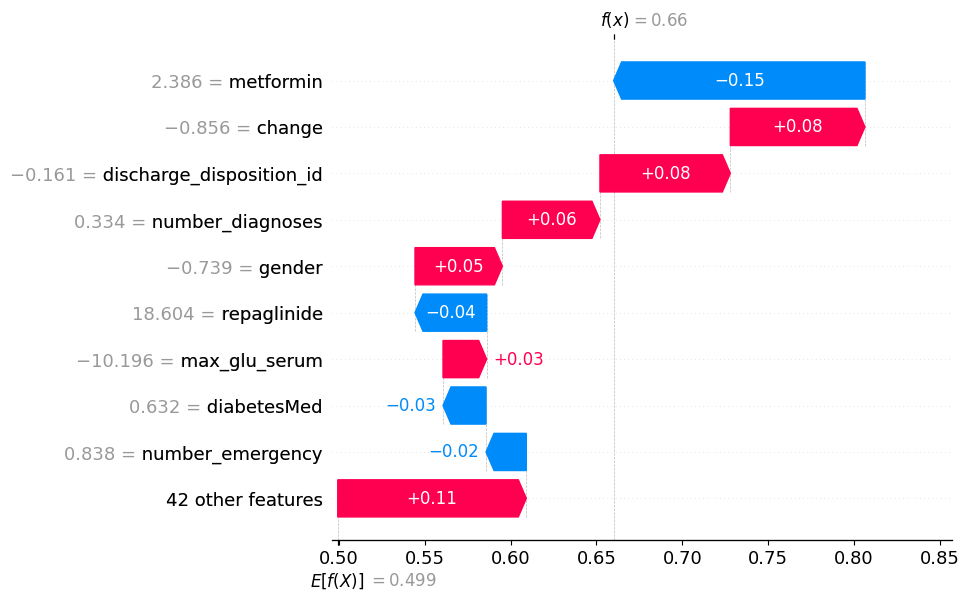

In [ ]:
import pandas as pd
import numpy as np
import joblib
import json
import shap
from lime.lime_tabular import LimeTabularExplainer

# --- Input Patient Data using Colab Forms ---
# Modify these values directly in the form fields that appear above this cell.

race_input = "Caucasian" # @param ["Caucasian", "AfricanAmerican", "Other", "Asian", "Hispanic"]
gender_input = "Female" # @param ["Female", "Male", "Unknown/Invalid"]
age_input = "[40-50)" # @param ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
admission_type_id_input = 1 # @param {type:"integer"}  # e.g., 1=Emergency, 2=Urgent, 3=Elective (typical range 1-8)
discharge_disposition_id_input = 3 # @param {type:"integer"} # e.g., 1=Discharged to home (typical range 1-28)
admission_source_id_input = 7 # @param {type:"integer"} # e.g., 7=Emergency Room (typical range 1-25)
time_in_hospital_input = 7 # @param {type:"integer"} # Number of days spent in hospital (typical range 1-14)
num_lab_procedures_input = 4 # @param {type:"integer"} # Number of lab procedures performed (typical range 1-132)
num_procedures_input = 0 # @param {type:"integer"} # Number of non-lab procedures performed (typical range 0-6)
num_medications_input = 15 # @param {type:"integer"} # Number of medications administered (typical range 1-81)
number_outpatient_input = 0 # @param {type:"integer"} # Number of outpatient visits in the year preceding the encounter (typical range 0-42)
number_emergency_input = 1 # @param {type:"integer"} # Number of emergency visits in the year preceding the encounter (typical range 0-76)
number_inpatient_input = 0 # @param {type:"integer"} # Number of inpatient visits in the year preceding the encounter (typical range 0-21)
number_diagnoses_input = 8 # @param {type:"integer"} # Number of diagnoses (typical range 1-16)
max_glu_serum_input = "None" # @param [">200", ">300", "Norm", "None"]
A1Cresult_input = "None" # @param [">7", ">8", "Norm", "None"]
metformin_input = "Steady" # @param ["No", "Up", "Down", "Steady"]
repaglinide_input = "Up" # @param ["No", "Up", "Down", "Steady"]
nateglinide_input = "No" # @param ["No", "Up", "Down", "Steady"]
chlorpropamide_input = "No" # @param ["No", "Up", "Down", "Steady"]
glimepiride_input = "No" # @param ["No", "Up", "Down", "Steady"]
acetohexamide_input = "No" # @param ["No", "Up", "Down", "Steady"]
glipizide_input = "No" # @param ["No", "Up", "Down", "Steady"]
glyburide_input = "No" # @param ["No", "Up", "Down", "Steady"]
tolbutamide_input = "No" # @param ["No", "Up", "Down", "Steady"]
pioglitazone_input = "No" # @param ["No", "Up", "Down", "Steady"]
rosiglitazone_input = "No" # @param ["No", "Up", "Down", "Steady"]
acarbose_input = "No" # @param ["No", "Up", "Down", "Steady"]
miglitol_input = "No" # @param ["No", "Up", "Down", "Steady"]
troglitazone_input = "No" # @param ["No", "Up", "Down", "Steady"]
tolazamide_input = "No" # @param ["No", "Up", "Down", "Steady"]
examide_input = "No" # @param ["No", "Up", "Down", "Steady"]
citoglipton_input = "No" # @param ["No", "Up", "Down", "Steady"]
insulin_input = "Down" # @param ["No", "Up", "Down", "Steady"]
glyburide_metformin_input = "No" # @param ["No", "Up", "Down", "Steady"]
glipizide_metformin_input = "No" # @param ["No", "Up", "Down", "Steady"]
glimepiride_pioglitazone_input = "No" # @param ["No", "Up", "Down", "Steady"]
metformin_rosiglitazone_input = "No" # @param ["No", "Up", "Down", "Steady"]
metformin_pioglitazone_input = "No" # @param ["No", "Up", "Down", "Steady"]
change_input = "Ch" # @param ["Ch", "No"]
diabetesMed_input = "Yes" # @param ["Yes", "No"]
diag_1_input = "428" # @param {type:"string"} # Primary diagnosis (ICD9 code or description, e.g., '250' for diabetes)
diag_2_input = "250" # @param {type:"string"} # Secondary diagnosis (ICD9 code or description, e.g., '428' for heart failure)
diag_3_input = "250" # @param {type:"string"} # Additional secondary diagnosis (ICD9 code or description, e.g., '401' for hypertension)

# Construct patient_data dictionary from form inputs
patient_data = {
    'race': race_input,
    'gender': gender_input,
    'age': age_input,
    'admission_type_id': admission_type_id_input,
    'discharge_disposition_id': discharge_disposition_id_input,
    'admission_source_id': admission_source_id_input,
    'time_in_hospital': time_in_hospital_input,
    'num_lab_procedures': num_lab_procedures_input,
    'num_procedures': num_procedures_input,
    'num_medications': num_medications_input,
    'number_outpatient': number_outpatient_input,
    'number_emergency': number_emergency_input,
    'number_inpatient': number_inpatient_input,
    'number_diagnoses': number_diagnoses_input,
    'max_glu_serum': max_glu_serum_input,
    'A1Cresult': A1Cresult_input,
    'metformin': metformin_input,
    'repaglinide': repaglinide_input,
    'nateglinide': nateglinide_input,
    'chlorpropamide': chlorpropamide_input,
    'glimepiride': glimepiride_input,
    'acetohexamide': acetohexamide_input,
    'glipizide': glipizide_input,
    'glyburide': glyburide_input,
    'tolbutamide': tolbutamide_input,
    'pioglitazone': pioglitazone_input,
    'rosiglitazone': rosiglitazone_input,
    'acarbose': acarbose_input,
    'miglitol': miglitol_input,
    'troglitazone': troglitazone_input,
    'tolazamide': tolazamide_input,
    'examide': examide_input,
    'citoglipton': citoglipton_input,
    'insulin': insulin_input,
    'glyburide-metformin': glyburide_metformin_input,
    'glipizide-metformin': glipizide_metformin_input,
    'glimepiride-pioglitazone': glimepiride_pioglitazone_input,
    'metformin-rosiglitazone': metformin_rosiglitazone_input,
    'metformin-pioglitazone': metformin_pioglitazone_input,
    'change': change_input,
    'diabetesMed': diabetesMed_input,
    'diag_1': diag_1_input,
    'diag_2': diag_2_input,
    'diag_3': diag_3_input
}

# Convert to DataFrame for consistent processing
input_df = pd.DataFrame([patient_data])

# --- Feature Engineering (using previously defined functions) ---
def safe_float(x):
    try:
        return float(x)
    except:
        return 0

def severity_score(code):
    if 390 <= code <= 459:
        return 3   # circulatory (high risk)
    elif 460 <= code <= 519:
        return 2   # respiratory
    elif 520 <= code <= 579:
        return 2   # digestive
    elif code == 250:
        return 3   # diabetes
    elif 800 <= code <= 999:
        return 1   # injury
    else:
        return 0   # others

input_df['previous_admissions'] = input_df['number_inpatient'] + input_df['number_emergency']
input_df['medication_load'] = input_df['num_medications']
input_df['time_since_last_visit'] = (
    input_df['number_outpatient'] * 30 +
    input_df['number_inpatient'] * 60 +
    input_df['number_emergency'] * 15
)

input_df['diag_1_num'] = input_df['diag_1'].apply(safe_float)
input_df['diag_2_num'] = input_df['diag_2'].apply(safe_float)
input_df['diag_3_num'] = input_df['diag_3'].apply(safe_float)

input_df['diag_severity'] = (
    input_df['diag_1_num'].apply(severity_score) +
    input_df['diag_2_num'].apply(severity_score) +
    input_df['diag_3_num'].apply(severity_score)
)

# --- Load Model and Preprocessing Tools (if not already loaded) ---
# This assumes 'artifacts' directory and files are available.
try:
    best_model = joblib.load('artifacts/model.joblib')
    scaler = joblib.load('artifacts/scaler.joblib')
    label_encoders_dict = joblib.load('artifacts/label_encoders_dict.joblib')
    with open('artifacts/feature_columns.json', 'r') as f:
        feature_columns = json.load(f)
    print("Loaded model, scaler, encoders, and feature columns from artifacts.")
except FileNotFoundError:
    print("Artifacts not found. Please ensure `TLDwB-8ItlF5` has been run to generate them.")
    raise

# --- Encode categorical features using the loaded dictionary of encoders ---
categorical_cols = [col for col in feature_columns if col in input_df.columns and input_df[col].dtype == 'object']

for col in categorical_cols:
    if col in label_encoders_dict: # Ensure we have an encoder for this column
        le = label_encoders_dict[col]
        # Convert to string and try to transform, handling unseen labels by converting to -1.
        input_df[col] = input_df[col].astype(str).apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)
    else:
        # Assign a default for unseen columns or other default if appropriate
        input_df[col] = -1

# Align columns with training data and ensure order
missing_cols = set(feature_columns) - set(input_df.columns)
for c in missing_cols:
    input_df[c] = 0 # Assume 0 for missing medication columns or other default if appropriate

# Filter and reorder columns to match the training data's feature_columns
input_df_aligned = input_df[feature_columns]

# --- Scale numerical features ---
scaled_input = scaler.transform(input_df_aligned)

# --- Make Prediction ---
prediction = best_model.predict(scaled_input)
prediction_proba = best_model.predict_proba(scaled_input)[0] # Get probabilities for both classes

print(f"\n--- Prediction Result ---")
if prediction[0] == 1:
    print(f"The model predicts: Patient IS likely to be readmitted (<30 days).")
else:
    print(f"The model predicts: Patient is NOT likely to be readmitted (NO or >30 days).")
print(f"Prediction probabilities: {prediction_proba[0]:.4f} (Not Readmitted), {prediction_proba[1]:.4f} (Readmitted <30 Days)")

# --- LIME Explanation ---
# Define the prediction function for LIME
def predict_proba_func_for_lime(data_to_predict):
    df_for_scaling = pd.DataFrame(data_to_predict, columns=feature_columns)
    scaled_data = scaler.transform(df_for_scaling)
    return best_model.predict_proba(scaled_data)

# LIME requires the original training data for context (assuming X_res is available globally)
try:
    # X_res should be available from previous cells (after SMOTE)
    training_data_for_lime = X_res.values
    print("Using globally available X_res for LIME training data.")
except NameError:
    print("X_res not found globally. LIME explainer cannot be initialized.")
    training_data_for_lime = np.zeros((1, len(feature_columns))) # Fallback, but will likely cause issues

# Get indices of categorical features in the feature_columns list
categorical_features_indices = []
for col_name in label_encoders_dict.keys(): # Iterate through original categorical column names
    if col_name in feature_columns:
        categorical_features_indices.append(feature_columns.index(col_name))

# Define class names for interpretability
class_names = ['Not Readmitted', 'Readmitted <30 Days'] # Assuming 0 for No, 1 for Yes

# Create the LIME Explainer
explainer_lime = LimeTabularExplainer(
    training_data=training_data_for_lime,
    feature_names=feature_columns,
    class_names=class_names,
    categorical_features=categorical_features_indices,
    mode='classification'
)

# Inverse transform to get the label-encoded, engineered features that LIME expects
instance_to_explain_processed_user_lime = scaler.inverse_transform(scaled_input)[0]

# Generate Explanation for the user-provided instance
explanation_user_lime = explainer_lime.explain_instance(
    data_row=instance_to_explain_processed_user_lime,
    predict_fn=predict_proba_func_for_lime,
    num_features=10 # Show top 10 features
)

print("\n--- LIME Explanation Plot for User Input ---")
explanation_user_lime.show_in_notebook(show_table=True, show_all=False)

# --- SHAP Explanation ---

# Create a SHAP TreeExplainer for the Random Forest model
explainer_shap = shap.TreeExplainer(best_model)

# Calculate SHAP values for the user-provided instance
shap_values_user = explainer_shap.shap_values(scaled_input)

# For binary classification with a single instance, shap_values_user is a 3D NumPy array
# of shape (1, num_features, num_classes). For example, (1, 51, 2).
# To get the SHAP values for class 1 for the single instance, we access the first (and only)
# instance using [0], and then select the column corresponding to class 1 across all features.
shap_values_user_class_1 = shap_values_user[0][:, 1]

print("\n--- SHAP Force Plot for User Input ---")
shap.force_plot(
    explainer_shap.expected_value[1],
    shap_values_user_class_1,
    feature_names=feature_columns,
    matplotlib=True, # Render with matplotlib for static output
    show=True
)

print("\n--- SHAP Waterfall Plot for User Input ---")
shap.waterfall_plot(shap.Explanation(values=shap_values_user_class_1,
                                  base_values=explainer_shap.expected_value[1],
                                  data=scaled_input[0],
                                  feature_names=feature_columns))

In [ ]:
print("\n--- Detailed Human-Readable Explanation ---")

predicted_class = class_names[prediction[0]]
proba_not_readmitted = prediction_proba[0]
proba_readmitted = prediction_proba[1]

print(f"The patient is predicted to be: **{predicted_class}**.")
print(f"This prediction has a probability of {proba_not_readmitted:.2f} for 'Not Readmitted' and {proba_readmitted:.2f} for 'Readmitted <30 Days'.")

print("\n### Key Factors Influencing This Prediction (LIME & SHAP):")

# LIME Explanation Summary
print("Based on LIME (Local Interpretable Model-agnostic Explanations):")
lime_features = explanation_user_lime.as_list()

# Sort LIME features by absolute weight for better interpretability
lime_features_sorted = sorted(lime_features, key=lambda x: abs(x[1]), reverse=True)

for feature, weight in lime_features_sorted[:5]: # Show top 5 features from LIME
    if weight > 0:
        print(f"- **{feature}** (tends to increase the chance of '{class_names[1]}')")
    else:
        print(f"- **{feature}** (tends to increase the chance of '{class_names[0]}')")

print("\nBased on SHAP (SHapley Additive exPlanations):")
# SHAP explanation summary (focus on feature importance for the predicted class)

# Combine SHAP values with feature names for class 1
shap_importance = pd.Series(shap_values_user_class_1, index=feature_columns)

# Sort by absolute SHAP value to find most impactful features
shap_importance_sorted = shap_importance.abs().sort_values(ascending=False)

# Display top 5 influential features from SHAP
for feature in shap_importance_sorted.index[:5]:
    value = shap_importance[feature]
    original_value = input_df_aligned[feature].iloc[0] # Get original (encoded/scaled) value for context

    if value > 0:
        print(f"- **{feature}** (SHAP value: {value:.3f}) pushing towards '{class_names[1]}'")
    else:
        print(f"- **{feature}** (SHAP value: {value:.3f}) pushing towards '{class_names[0]}'")

print("\nThese explanations highlight the features that most strongly influenced the model's decision for this particular patient.")


--- Detailed Human-Readable Explanation ---
The patient is predicted to be: **Readmitted <30 Days**.
This prediction has a probability of 0.34 for 'Not Readmitted' and 0.66 for 'Readmitted <30 Days'.

### Key Factors Influencing This Prediction (LIME & SHAP):
Based on LIME (Local Interpretable Model-agnostic Explanations):
- **change=0** (tends to increase the chance of 'Readmitted <30 Days')
- **rosiglitazone=1** (tends to increase the chance of 'Readmitted <30 Days')
- **pioglitazone=1** (tends to increase the chance of 'Readmitted <30 Days')
- **metformin=2** (tends to increase the chance of 'Not Readmitted')
- **miglitol=1** (tends to increase the chance of 'Not Readmitted')

Based on SHAP (SHapley Additive exPlanations):
- **metformin** (SHAP value: -0.146) pushing towards 'Not Readmitted'
- **change** (SHAP value: 0.078) pushing towards 'Readmitted <30 Days'
- **discharge_disposition_id** (SHAP value: 0.076) pushing towards 'Readmitted <30 Days'
- **number_diagnoses** (SHAP valu

In [ ]:
print("\n--- Human-Readable Explanation (Paragraph Format) ---")

predicted_class = class_names[prediction[0]]
proba_not_readmitted = prediction_proba[0]
proba_readmitted = prediction_proba[1]

explanation_text = (
    f"For this patient, the model predicts that they are **{predicted_class}** "
    f"with a probability of {proba_not_readmitted:.2f} for 'Not Readmitted' and {proba_readmitted:.2f} for 'Readmitted <30 Days'. "
    f"This prediction is primarily influenced by several key factors.\n\n"
)

explanation_text += "Based on **LIME (Local Interpretable Model-agnostic Explanations)**: "
lime_features_summary = []
for feature, weight in lime_features_sorted[:5]: # Show top 5 features from LIME
    if weight > 0:
        lime_features_summary.append(f"'{feature}' (increasing the chance of '{class_names[1]}')")
    else:
        lime_features_summary.append(f"'{feature}' (increasing the chance of '{class_names[0]}')")
explanation_text += "Features like " + ", ".join(lime_features_summary) + ".\n\n"

explanation_text += "Furthermore, **SHAP (SHapley Additive exPlanations)** indicates that "
shap_features_summary = []
for feature in shap_importance_sorted.index[:5]:
    value = shap_importance[feature]
    if value > 0:
        shap_features_summary.append(f"'{feature}' (pushing towards '{class_names[1]}' with a SHAP value of {value:.3f})")
    else:
        shap_features_summary.append(f"'{feature}' (pushing towards '{class_names[0]}' with a SHAP value of {value:.3f})")
explanation_text += "factors such as " + ", ".join(shap_features_summary) + ".\n\n"

explanation_text += (
    "These combined insights from LIME and SHAP highlight the most critical features "
    "that led the model to this specific outcome for the individual patient."
)

print(explanation_text)


--- Human-Readable Explanation (Paragraph Format) ---
For this patient, the model predicts that they are **Readmitted <30 Days** with a probability of 0.34 for 'Not Readmitted' and 0.66 for 'Readmitted <30 Days'. This prediction is primarily influenced by several key factors.

Based on **LIME (Local Interpretable Model-agnostic Explanations)**: Features like 'change=0' (increasing the chance of 'Readmitted <30 Days'), 'rosiglitazone=1' (increasing the chance of 'Readmitted <30 Days'), 'pioglitazone=1' (increasing the chance of 'Readmitted <30 Days'), 'metformin=2' (increasing the chance of 'Not Readmitted'), 'miglitol=1' (increasing the chance of 'Not Readmitted').

Furthermore, **SHAP (SHapley Additive exPlanations)** indicates that factors such as 'metformin' (pushing towards 'Not Readmitted' with a SHAP value of -0.146), 'change' (pushing towards 'Readmitted <30 Days' with a SHAP value of 0.078), 'discharge_disposition_id' (pushing towards 'Readmitted <30 Days' with a SHAP value of

In [ ]:
!pip install -q groq

import os
from groq import Groq
from google.colab import userdata

client = Groq(api_key=userdata.get("GROQ_API_KEY"))

models = client.models.list()
for m in models.data:
    print(m.id)

openai/gpt-oss-20b
allam-2-7b
canopylabs/orpheus-arabic-saudi
meta-llama/llama-prompt-guard-2-86m
openai/gpt-oss-safeguard-20b
openai/gpt-oss-120b
whisper-large-v3
meta-llama/llama-prompt-guard-2-22m
canopylabs/orpheus-v1-english
whisper-large-v3-turbo
qwen/qwen3.8-27b


In [ ]:
!pip install -q groq

from groq import Groq
from google.colab import userdata

client = Groq(api_key=userdata.get("GROQ_API_KEY"))

def generate_llm_explanation(prediction, prediction_proba, top_lime, top_shap, patient_data):
    prob_readmit = prediction_proba[1]
    predicted_label = "likely to be readmitted within 30 days" if prediction == 1 else "not likely to be readmitted within 30 days"

    prompt = f"""You are helping a clinician understand a machine learning model's prediction
about hospital readmission risk. Do not give medical advice or treatment recommendations —
only explain *why the model made this prediction*, based on the feature contributions below.

Prediction: {predicted_label}
Probability of readmission within 30 days: {prob_readmit:.1%}

Top contributing factors (LIME):
{top_lime}

Top contributing factors (SHAP, feature/shap_value/scaled_value):
{top_shap}

Relevant patient record fields: {patient_data}

Write a short (10-15 sentence), plain-English explanation of what drove this specific prediction.
Refer to features by their real-world meaning, not raw column names. Do not invent numbers that
weren't given to you. End with one sentence noting this is a model output to support review."""

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[{"role": "user", "content": prompt}]
    )
    return response.choices[0].message.content

# Define the missing variables from previous outputs
top_lime = "\n".join([f"{feat}: {weight:.4f}" for feat, weight in lime_features_sorted[:5]])
top_shap = "\n".join([f"{feat}: {shap_importance[feat]:.4f}" for feat in shap_importance_sorted.index[:5]])

explanation_text = generate_llm_explanation(
    prediction[0], prediction_proba, top_lime, top_shap, patient_data
)
import textwrap

print(textwrap.fill(explanation_text,width=150))

The model flagged the patient’s recent medication change as an important factor that pushes the readmission risk upward. Even though the patient’s
metformin dose is listed as “steady,” the algorithm assigns a modest negative contribution to metformin use, meaning it slightly reduces the predicted
risk. Conversely, the model interprets the presence (or recent use) of the thiazolidinedione drugs rosiglitazone and pioglitazone as strong positive
drivers of risk, each adding a sizable bump to the score. The lack of miglitol, an alpha‑glucosidase inhibitor, is also interpreted as a small
risk‑lowering signal. Beyond medications, the patient’s discharge disposition (code 3, which typically corresponds to discharge to home with self‑care
or a similar setting) adds to the risk, perhaps because patients leaving without additional support are more likely to return. The record shows eight
documented diagnoses, and a higher count of distinct diagnoses is another factor that nudges the prediction u